## You are the junior data analyst supporting an online retailer. Leaders want to understand what is happening across
their transaction history before deciding where to focus commercial effort.

<br>

### YOUR MANDATE
Use exploratory data analysis (EDA) to examine transaction quality, sales patterns, product performance, customer
behavior, geographic mix, and cancellations/returns. Turn the evidence into concise, cautious recommendations a
business team could investigate.


### The decisions your analysis should support
• Where should the business investigate sales growth or volatility?<br>
• Which products and product groups deserve a closer commercial review?<br>
• What patterns appear across customer groups, countries, and order sizes?<br>
• How might returns, cancellations, missing identifiers, or data-quality problems affect the interpretation?<br>
• What should management examine next, and what evidence would it need before acting?

### Install the Python libraries

In [1]:
!pip install pandas numpy seaborn matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# df = pd.read_excel(
#     "OnlineRetail.xlsx"
# )

df = pd.read_csv('OnlineRetail.csv')

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

        InvoiceDate  UnitPrice  CustomerID         Country  
0  12-01-2010 08:26       2.55     17850.0  United Kingdom  
1  12-01-2010 08:26       3.39     17850.0  United Kingdom  
2  12-01-2010 08:26       2.75     17850.0  United Kingdom  
3  12-01-2010 08:26       3.39     17850.0  United Kingdom  
4  12-01-2010 08:26       3.39     17850.0  United Kingdom  


In [6]:
print("Dataset dimenstions:")

print(df.shape)

Dataset dimenstions:
(541909, 8)


In [7]:
print("Column names:")
print(df.columns.tolist())

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [8]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


### Check for missing values

In [9]:
missing_values = df.isna().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


### Check the trnsaction dates

In [10]:
print(df["InvoiceDate"].dtype)

object


In [13]:
# df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True, errors="coerce")

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="mixed", dayfirst=True)

print(df["InvoiceDate"].dt.strftime("%m-%d-%y %I:%M:%S %p").head())


# print(df["InvoiceDate"].head())

# df.info()

0    01-12-10 08:26:00 AM
1    01-12-10 08:26:00 AM
2    01-12-10 08:26:00 AM
3    01-12-10 08:26:00 AM
4    01-12-10 08:26:00 AM
Name: InvoiceDate, dtype: object


In [14]:
invalid_dates = df['InvoiceDate'].isna().sum()

print("Missing or invalid dates:", invalid_dates)

Missing or invalid dates: 0


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


### Exporing the data

In [16]:
print("Earliest transaction:")

print(df["InvoiceDate"].min())

Earliest transaction:
2010-01-12 08:26:00


In [17]:
print("Latest transaction:")

print(df["InvoiceDate"].max())

Latest transaction:
2011-12-10 17:19:00


In [18]:
print("Number of different countries:")

print(df["Country"].nunique())

Number of different countries:
38


In [19]:
print("Names of different countries:")

for country in df["Country"].unique():
  print(country)

Names of different countries:
United Kingdom
France
Australia
Netherlands
Germany
Norway
EIRE
Switzerland
Spain
Poland
Portugal
Italy
Belgium
Lithuania
Japan
Iceland
Channel Islands
Denmark
Cyprus
Sweden
Austria
Israel
Finland
Bahrain
Greece
Hong Kong
Singapore
Lebanon
United Arab Emirates
Saudi Arabia
Czech Republic
Canada
Unspecified
Brazil
USA
European Community
Malta
RSA


### Handling null values

In [20]:
missing_summary = pd.DataFrame({
    "Missing_count" : df.isna().sum(),
    "Missing_percentage:" : (
        df.isna().mean() * 100
    ).round(2)
})

missing_summary

,Missing_count,Missing_percentage:
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [21]:
df_eda = df.copy()

print("Missing descriptions before:", df_eda["Description"].isna().sum())

Missing descriptions before: 1454


In [22]:
description_counts = (
    df_eda.dropna(subset=["Description"]).groupby("StockCode")["Description"].nunique()
)

In [23]:
unambiguous_codes = description_counts[description_counts == 1].index

print(unambiguous_codes[:5])

Index(['10002', '10120', '10123C', '10124A', '10124G'], dtype='object', name='StockCode')


In [24]:
description_map = (
    df_eda[
        df_eda["StockCode"].isin(unambiguous_codes)
    ].dropna(subset=["Description"]).drop_duplicates(subset=['StockCode'])
    .set_index("StockCode")["Description"]
)

print(description_map.head())

StockCode
84029G    KNITTED UNION FLAG HOT WATER BOTTLE
84029E         RED WOOLLY HOTTIE WHITE HEART.
22752            SET 7 BABUSHKA NESTING BOXES
21730       GLASS STAR FROSTED T-LIGHT HOLDER
22633                  HAND WARMER UNION JACK
Name: Description, dtype: object


In [25]:
# Filling missing description

df_eda['Description'] = df_eda["Description"].fillna(
    df_eda["StockCode"].map(description_map)
)

In [26]:
df_eda["Description"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 541909 entries, 0 to 541908
Series name: Description
Non-Null Count   Dtype 
--------------   ----- 
541488 non-null  object
dtypes: object(1)
memory usage: 4.1+ MB


In [27]:
df_eda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  541488 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [28]:
# verify whether our cleaning worked or not?

missing_after = df_eda['Description'].isna().sum()

print("Missing description after:",missing_after )

Missing description after: 421


In [29]:
df_eda["Description"] = df_eda["Description"].fillna("Uknown")

In [30]:
print(df_eda['Description'].isna().sum())

0


### Handling missing customerid values

In [31]:
missing_customers = df_eda["CustomerID"].isna().sum()

known_customers = df_eda["CustomerID"].notna().sum()

missing_percentage = (
    df_eda["CustomerID"].isna().mean() * 100
)

print("Missing CustomerIDs:", missing_customers)
print("Known CustomerIDs:", known_customers)
print("Missing percentage:", round(missing_percentage, 2),"%")

Missing CustomerIDs: 135080
Known CustomerIDs: 406829
Missing percentage: 24.93 %


In [32]:
df_eda["CustomerID"] = (
    df_eda["CustomerID"].astype("Int64")
)

print(df_eda["CustomerID"].dtype) # missing => <NA>

Int64


In [33]:
known_customer_data = df_eda[
    df_eda["CustomerID"].notna()
].copy()

print(known_customer_data.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-01-12 08:26:00       2.55       17850  United Kingdom  
1 2010-01-12 08:26:00       3.39       17850  United Kingdom  
2 2010-01-12 08:26:00       2.75       17850  United Kingdom  
3 2010-01-12 08:26:00       3.39       17850  United Kingdom  
4 2010-01-12 08:26:00       3.39       17850  United Kingdom  


In [34]:
known_customer_data.shape

(406829, 8)

In [35]:
print("Rows available for customer analysis:", len(known_customer_data))

Rows available for customer analysis: 406829


### The decisions your analysis should support
• Where should the business investigate sales growth or volatility?<br>
• Which products and product groups deserve a closer commercial review?<br>
• What patterns appear across customer groups, countries, and order sizes?<br>
• How might returns, cancellations, missing identifiers, or data-quality problems affect the interpretation?<br>
• What should management examine next, and what evidence would it need before acting?

In [36]:
#  Where should the business investigate sales growth or volatility?

known_customer_data["LineTotal"] = known_customer_data["Quantity"] * known_customer_data["UnitPrice"]

known_customer_data["Month"] = (
    known_customer_data["InvoiceDate"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_sales = (
    known_customer_data.groupby("Month", as_index=False).agg(
        MonthlySales = ("LineTotal", "sum"),
        TotalOrder = ("InvoiceNo", "nunique"),
        UnitsSold = ("Quantity", "sum")
    )
)

print(monthly_sales)

        Month  MonthlySales  TotalOrder  UnitsSold
0  2010-01-01     46051.260         127      24032
1  2010-02-01     45775.430         160      20855
2  2010-03-01     22598.460          64      11548
3  2010-05-01     31380.600          94      16394
4  2010-06-01     30465.080         111      16095
5  2010-07-01     53125.990          79      19351
6  2010-08-01     38048.680         134      21275
7  2010-09-01     37177.850         132      16904
8  2010-10-01     32005.350          78      15388
9  2010-12-01    217975.320         729     134520
10 2011-01-01    510308.100        1514     302399
11 2011-02-01    479089.930        1282     287199
12 2011-03-01    617490.300        1565     361459
13 2011-04-01    556556.961        1528     351485
14 2011-05-01    704359.400        1806     409448
15 2011-06-01    663888.110        1908     398277
16 2011-07-01    706117.571        1863     432711
17 2011-08-01    583211.860        1680     353339
18 2011-09-01    901380.352    

In [37]:
# Calculate month-over-month growth

monthly_sales["SalesGrowthpct"] = (
    monthly_sales["MonthlySales"]
    .pct_change()
    * 100
)

monthly_sales["SalesGrowthpct"] = monthly_sales["SalesGrowthpct"].round(2)

print(
    monthly_sales[
        ["Month", "MonthlySales", "SalesGrowthpct"]
    ]
)

        Month  MonthlySales  SalesGrowthpct
0  2010-01-01     46051.260             NaN
1  2010-02-01     45775.430           -0.60
2  2010-03-01     22598.460          -50.63
3  2010-05-01     31380.600           38.86
4  2010-06-01     30465.080           -2.92
5  2010-07-01     53125.990           74.38
6  2010-08-01     38048.680          -28.38
7  2010-09-01     37177.850           -2.29
8  2010-10-01     32005.350          -13.91
9  2010-12-01    217975.320          581.06
10 2011-01-01    510308.100          134.11
11 2011-02-01    479089.930           -6.12
12 2011-03-01    617490.300           28.89
13 2011-04-01    556556.961           -9.87
14 2011-05-01    704359.400           26.56
15 2011-06-01    663888.110           -5.75
16 2011-07-01    706117.571            6.36
17 2011-08-01    583211.860          -17.41
18 2011-09-01    901380.352           54.55
19 2011-10-01    820252.470           -9.00
20 2011-11-01   1004792.270           22.50
21 2011-12-01    198014.470     

In [38]:
known_customer_data["Month"].head()

,Month
0,2010-01-01
1,2010-01-01
2,2010-01-01
3,2010-01-01
4,2010-01-01


### Monthly Sales

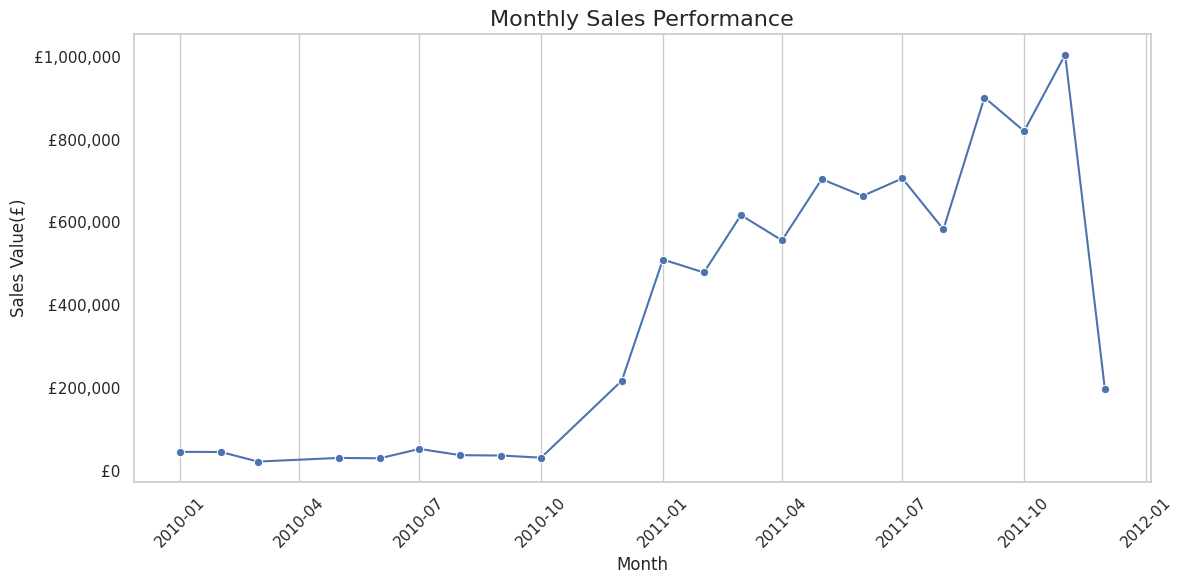

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="MonthlySales",
    marker="o",
    ax=ax
)

ax.set_title("Monthly Sales Performance", fontsize=16)

ax.set_xlabel("Month")
ax.set_ylabel("Sales Value(£)")

ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("£{x:,.0f}")
)

ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y")

plt.tight_layout()
plt.show()

In [40]:
# Find the largest monthly increase or decrease

growth_data =  monthly_sales.dropna(
    subset=["SalesGrowthpct"]
)

largest_increase = growth_data.loc[
    growth_data["SalesGrowthpct"].idxmax()
]

largest_decrease = growth_data.loc[
    growth_data["SalesGrowthpct"].idxmin()
]

print("Largest monthly increase:")
print(largest_increase[[
    "Month", "MonthlySales", "SalesGrowthpct"
]])

Largest monthly increase:
Month             2010-12-01 00:00:00
MonthlySales                217975.32
SalesGrowthpct                 581.06
Name: 9, dtype: object


In [41]:
print("Largest monthly decrease:")
print(largest_decrease[[
    "Month", "MonthlySales", "SalesGrowthpct"
]])

Largest monthly decrease:
Month             2011-12-01 00:00:00
MonthlySales                198014.47
SalesGrowthpct                 -80.29
Name: 21, dtype: object


In [42]:
# Which products and product groups deserve a closer commercial review?

known_customer_data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850,United Kingdom,15.30,2010-01-01
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,20.34,2010-01-01
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850,United Kingdom,22.00,2010-01-01
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,20.34,2010-01-01
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,20.34,2010-01-01


In [43]:
sales = known_customer_data.copy()

print(
    sales[
        ["InvoiceNo","StockCode", "Description",
         "Quantity", "UnitPrice", "LineTotal"]
    ].tail()
)

       InvoiceNo StockCode                      Description  Quantity  \
541904    581587     22613      PACK OF 20 SPACEBOY NAPKINS        12   
541905    581587     22899     CHILDREN'S APRON DOLLY GIRL          6   
541906    581587     23254    CHILDRENS CUTLERY DOLLY GIRL          4   
541907    581587     23255  CHILDRENS CUTLERY CIRCUS PARADE         4   
541908    581587     22138    BAKING SET 9 PIECE RETROSPOT          3   

        UnitPrice  LineTotal  
541904       0.85      10.20  
541905       2.10      12.60  
541906       4.15      16.60  
541907       4.15      16.60  
541908       4.95      14.85  


In [44]:
sales_sorted = sales.sort_values(
    by="LineTotal",
    ascending=True
)

sales_sorted.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineTotal,Month
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-09-12 09:27:00,2.08,16446,United Kingdom,-168469.60,2011-09-01
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom,-77183.60,2011-01-01
222681,C556445,M,Manual,-1,2011-10-06 15:31:00,38970.00,15098,United Kingdom,-38970.00,2011-10-01
422375,C573079,M,Manual,-2,2011-10-27 14:15:00,4161.06,12536,France,-8322.12,2011-10-01
173277,C551685,POST,POSTAGE,-1,2011-03-05 12:51:00,8142.75,16029,United Kingdom,-8142.75,2011-03-01


In [45]:
product_summary = (
    sales.groupby("StockCode", as_index=False).
    agg(
        ProductDescription=("Description", "first"),
        SalesValue=("LineTotal", "sum"),
        UnitsSold=("Quantity", "sum"),
        InvoiceCount=("InvoiceNo","nunique"),
        AverageUnitPrice=("UnitPrice", "mean")
    )
)

In [46]:
product_summary.tail(5)

,StockCode,ProductDescription,SalesValue,UnitsSold,InvoiceCount,AverageUnitPrice
3679,D,Discount,-5696.220,-1194,65,72.484545
3680,DOT,DOTCOM POSTAGE,11906.360,16,16,744.147500
3681,M,Manual,-58385.460,3184,412,334.425634
3682,PADS,PADS TO MATCH ALL CUSHIONS,0.003,4,4,0.000750
3683,POST,POSTAGE,66710.240,3002,1194,37.888528


In [47]:
# Find the top 10 products by sales value

top_product_sales = (
    product_summary.nlargest(10, "SalesValue")
)

print(top_product_sales[
    ["StockCode", "ProductDescription", "SalesValue"]
].head(1))

     StockCode        ProductDescription  SalesValue
1292     22423  REGENCY CAKESTAND 3 TIER    132870.4


In [48]:
# Find the bottom 10 products by sales value

bottom_product_sales = (
    product_summary.nsmallest(10, "SalesValue")
)

print(bottom_product_sales[
    ["StockCode", "ProductDescription", "SalesValue"]
].head(1))

     StockCode ProductDescription  SalesValue
3681         M             Manual   -58385.46


• What patterns appear across customer groups, countries, and order sizes?

In [49]:
df_eda.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850,United Kingdom


In [50]:
# Creating a separate dataset

sales_all = df_eda.copy()

is_cancellation = (
    sales_all["InvoiceNo"]
    .astype(str).str.startswith("C")
)

# Selecting positive sales line

sales_all = sales_all[
    (~is_cancellation) & (sales_all["Quantity"] > 0) & (sales_all["UnitPrice"] > 0)
]

In [51]:
sales_all["LineTotal"] = (
    sales_all["Quantity"] * sales_all["UnitPrice"]
)

print("Eligible transaction lines:", len(sales_all))

print("Missing customer id:", sales_all["CustomerID"].isna().sum())

Eligible transaction lines: 530104
Missing customer id: 132220


In [52]:
print(sales_all.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  LineTotal  
0 2010-01-12 08:26:00       2.55       17850  United Kingdom      15.30  
1 2010-01-12 08:26:00       3.39       17850  United Kingdom      20.34  
2 2010-01-12 08:26:00       2.75       17850  United Kingdom      22.00  
3 2010-01-12 08:26:00       3.39       17850  United Kingdom      20.34  
4 2010-01-12 08:26:00       3.39       17850  United Kingdom      20.34  


In [53]:
# Calculate sales, order count, and customer count by country

orders_all = (
    sales_all.groupby(["InvoiceNo", "Country"], as_index=False)
    .agg(
        OrderValue=("LineTotal", "sum"),
        UnitsInOrder=("Quantity","sum"),
        ProductLines=("StockCode","size"),
        UniqueProducts=("StockCode", "nunique")
    )
)

len(orders_all)

19960

In [54]:
# Compare the countries

country_summary = (
    orders_all
    .groupby("Country", as_index=False)
    .agg(
        TotalSales=("OrderValue", "sum"),
        TotalOrder=("InvoiceNo","nunique"),
        AverageOrderValue=("OrderValue", "mean"),
        UnitsSold=("UnitsInOrder","sum")
    )
)

country_summary = country_summary.sort_values(
    "AverageOrderValue", ascending=False
)

country_summary.head(10)

,Country,TotalSales,TotalOrder,AverageOrderValue,UnitsSold
30,Singapore,21279.29,7,3039.898571,5241
24,Netherlands,285446.34,94,3036.663191,200361
0,Australia,138521.31,57,2430.198421,83901
20,Japan,37416.37,19,1969.282632,26016
21,Lebanon,1693.88,1,1693.880000,386
16,Hong Kong,15691.80,11,1426.527273,4773
4,Brazil,1143.60,1,1143.600000,356
32,Sweden,38378.33,36,1066.064722,36083
33,Switzerland,57089.90,54,1057.220370,30629
9,Denmark,18955.34,18,1053.074444,8235


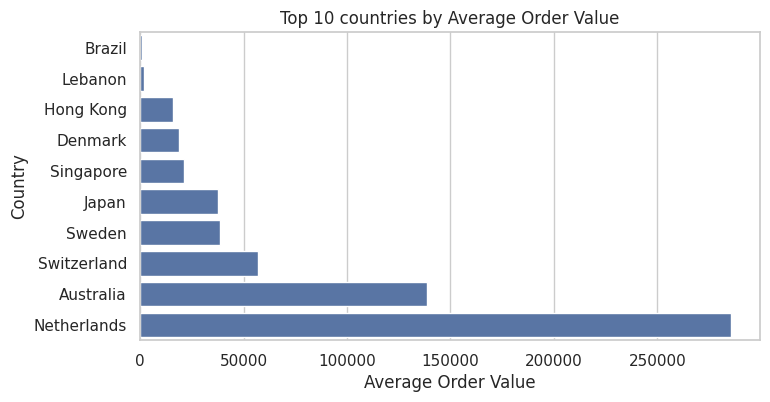

In [55]:
# Visualize the top 10 countries by average order value

top_10_countries = (
    country_summary.nlargest(10, "AverageOrderValue").sort_values("TotalSales")
)

fig, ax = plt.subplots(figsize=(8, 4))

sns.barplot(
    data=top_10_countries,
    x="TotalSales",
    y="Country",
    ax=ax
)

ax.set_title("Top 10 countries by Average Order Value")
ax.set_xlabel("Average Order Value")
ax.set_ylabel("Country")

plt.show()

In [56]:
# One-time customers from repeat customers

customer_sales = sales_all[
    sales_all["CustomerID"].notna()
]

customer_summary = (
    customer_sales
    .groupby("CustomerID", as_index=False)
    .agg(
        TotalSpend=("LineTotal", "sum"),
        InvoiceCount=("InvoiceNo", 'nunique'),
        TotalUnits=("Quantity", "sum")
    )
)

customer_summary.head()

,CustomerID,TotalSpend,InvoiceCount,TotalUnits
0,12346,77183.60,1,74215
1,12347,4310.00,7,2458
2,12348,1797.24,4,2341
3,12349,1757.55,1,631
4,12350,334.40,1,197


In [57]:
# Classify customer by invoice count

customer_summary["CustomerGroup"] = np.where(
    customer_summary["InvoiceCount"] > 1, "Repeat customer", "One time customer"
)

customer_summary.head()

,CustomerID,TotalSpend,InvoiceCount,TotalUnits,CustomerGroup
0,12346,77183.60,1,74215,One time customer
1,12347,4310.00,7,2458,Repeat customer
2,12348,1797.24,4,2341,Repeat customer
3,12349,1757.55,1,631,One time customer
4,12350,334.40,1,197,One time customer


In [58]:
# Rank customer by total spend

customer_summary.sort_values("TotalSpend", ascending=False).head()

,CustomerID,TotalSpend,InvoiceCount,TotalUnits,CustomerGroup
1689,14646,280206.02,73,196915,Repeat customer
4201,18102,259657.30,60,64124,Repeat customer
3728,17450,194550.79,46,69993,Repeat customer
3008,16446,168472.50,2,80997,Repeat customer
1879,14911,143825.06,201,80265,Repeat customer


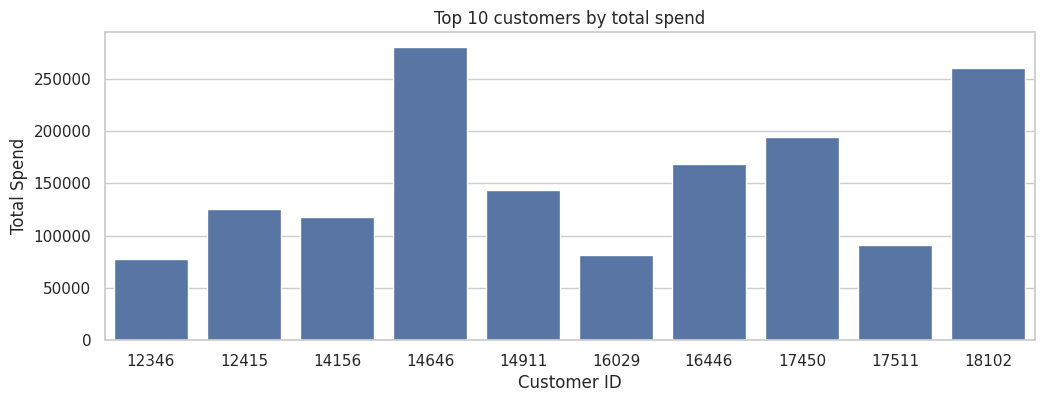

In [59]:
# Top 10 customers by total spend

top_10_customers = (
    customer_summary.nlargest(10, "TotalSpend")
    .sort_values("TotalSpend")
)

fig, ax = plt.subplots(figsize=(12, 4))

sns.barplot(
    data=top_10_customers,
    x="CustomerID",
    y="TotalSpend",
    ax=ax
)

ax.set_title("Top 10 customers by total spend")
ax.set_xlabel("Customer ID")
ax.set_ylabel("Total Spend")

plt.show()

 How might returns, cancellations, missing identifiers, or data-quality problems affect the interpretation?




In [60]:
# Understand how data quality issues affect business decisions

# Sales = £ 50,000

# Returs?
# Cancellations?
# Missing customer id
# Data-quality issues

In [61]:
# Identify cancellation and return related records

quality_data = df_eda.copy()

quality_data["IsCancellation"] = (
    quality_data["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
)

quality_data["LineTotal"] = (
    quality_data["Quantity"] * quality_data["UnitPrice"]
)

print("Total records:", len(quality_data))

print()

print("Cancellation-style records:", quality_data["IsCancellation"].sum())

print()

print("Negative-quantity records:", (quality_data["Quantity"] <0).sum())

print()

print("Zero-quantity records:", (quality_data["Quantity"] == 0).sum())

print()

print("Negative-price records:", (quality_data["UnitPrice"] <0).sum())

print()

print("Zero-price records:", (quality_data["UnitPrice"] == 0).sum())

Total records: 541909

Cancellation-style records: 9288

Negative-quantity records: 10624

Zero-quantity records: 0

Negative-price records: 2

Zero-price records: 2515


In [62]:
# Investigate negative-quantity records

negative_quantity_records = quality_data[
    quality_data["Quantity"] < 0
]

print("Negative-quantity transaction lines:", len(negative_quantity_records))

print()

print("Distinct invoice involved:", negative_quantity_records["InvoiceNo"].nunique())

print()

print("Signed value of negative-quantity lines(£):", round(negative_quantity_records["LineTotal"].sum(), 2))


Negative-quantity transaction lines: 10624

Distinct invoice involved: 5172

Signed value of negative-quantity lines(£): -896812.49


In [63]:
negative_quantity_records[
 [
     "InvoiceNo",
     "InvoiceDate",
     "StockCode",
     "Quantity",
     "UnitPrice",
     "LineTotal"
 ]
].head(10)

,InvoiceNo,InvoiceDate,StockCode,Quantity,UnitPrice,LineTotal
141,C536379,2010-01-12 09:41:00,D,-1,27.50,-27.50
154,C536383,2010-01-12 09:49:00,35004C,-1,4.65,-4.65
235,C536391,2010-01-12 10:24:00,22556,-12,1.65,-19.80
236,C536391,2010-01-12 10:24:00,21984,-24,0.29,-6.96
237,C536391,2010-01-12 10:24:00,21983,-24,0.29,-6.96
238,C536391,2010-01-12 10:24:00,21980,-24,0.29,-6.96
239,C536391,2010-01-12 10:24:00,21484,-12,3.45,-41.40
240,C536391,2010-01-12 10:24:00,22557,-12,1.65,-19.80
241,C536391,2010-01-12 10:24:00,22553,-24,1.65,-39.60
939,C536506,2010-01-12 12:38:00,22960,-6,4.25,-25.50


In [64]:
# Measure how missing CustomerIDs affect the analysis

missing_customer_count = (
    quality_data["CustomerID"].isna().sum()
)

known_customer_count = (
    quality_data["CustomerID"].notna().sum()
)

missing_customer_pct = (
    quality_data["CustomerID"].isna().mean() * 100
)

print("Records with missing CustomerID", missing_customer_count)

print()

print("Records with known CustomerID", known_customer_count)

print()


print("Percentage missing:", round(missing_customer_pct, 2),"%")

Records with missing CustomerID 135080

Records with known CustomerID 406829

Percentage missing: 24.93 %


What should management examine next, and what evidence would it need before acting?

In [65]:
analysis_data = df_eda.copy()

analysis_data["IsCancellation"] = (
    analysis_data["InvoiceNo"]
    .astype(str).str.startswith("C")
)

# Selecting positive sales line

sales_line = analysis_data[
    (~analysis_data["IsCancellation"]) & (sales_all["Quantity"] > 0) & (sales_all["UnitPrice"] > 0)
]

analysis_data["LineTotal"] = (
    sales_all["Quantity"] * sales_all["UnitPrice"]
)

In [66]:
print("All analysis records:", len(analysis_data))

print("Eligible positive sales line", len(sales_line))

print("Missing customer ids in sales:", sales_line["CustomerID"].isna().sum())

All analysis records: 541909
Eligible positive sales line 530104
Missing customer ids in sales: 132220


In [73]:
analysis_data

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsCancellation,LineTotal
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850,United Kingdom,False,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,False,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850,United Kingdom,False,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,False,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,False,20.34
...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-09-12 12:50:00,0.85,12680,France,False,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-09-12 12:50:00,2.10,12680,France,False,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-09-12 12:50:00,4.15,12680,France,False,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-09-12 12:50:00,4.15,12680,France,False,16.60


In [75]:
# Build an invoice-level table

orders = (
    analysis_data.groupby(
        ["InvoiceNo", "Country"], as_index=False
    ).
    agg(
        OrderValue=("LineTotal", "sum"),
        UnitsInOrder=("Quantity", "sum"),
        InvoiceDate=("InvoiceDate", "min")
    )
)

In [76]:
# calculate country-level business metrics

country_summabry = (
    orders.groupby("Country", as_index=False)
    .agg(
        TotalSales=("OrderValue", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        MedianOrderValue=("OrderValue", "median"),
        AverageOrderValue=("OrderValue", "mean")
    ).sort_values("TotalSales", ascending=False)
)

In [77]:
country_summary.head()

,Country,TotalSales,TotalOrders,MedianOrderValue,AverageOrderValue
36,United Kingdom,9025222.084,23494,198.275,384.150084
24,Netherlands,285446.340,101,637.720,2826.201386
10,EIRE,283453.960,360,484.380,787.372111
14,Germany,228867.140,603,246.540,379.547496
13,France,209715.110,461,327.230,454.913471


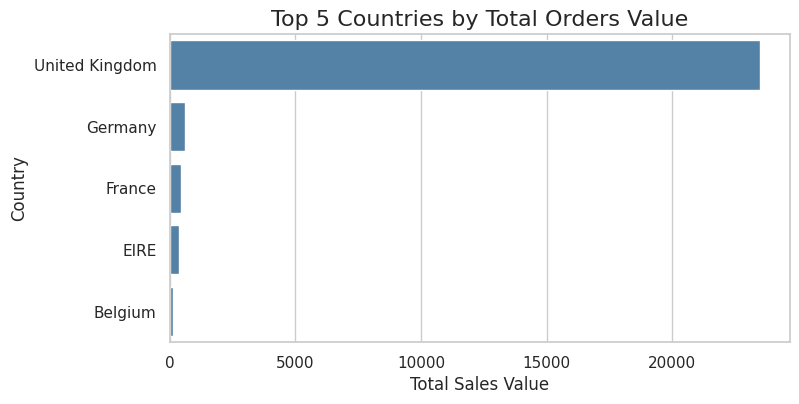

In [83]:
top_5_countries = (
    country_summary
    .nlargest(5, "TotalOrders")
    .sort_values("TotalOrders", ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 4))

sns.barplot(
    data=top_5_countries,
    x="TotalOrders",
    y="Country",
    color="steelblue",
    ax=ax
)

ax.set_title(
    "Top 5 Countries by Total Orders Value",
    fontsize=16
)

ax.set_xlabel(
    "Total Sales Value"
)

ax.set_ylabel(
    "Country"
)

plt.show()